In [12]:
# 1. Setup and Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from scipy import stats
import warnings

warnings.filterwarnings('ignore')

# Set style for better visualizations
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

print("Libraries imported successfully!")

Libraries imported successfully!


In [13]:
# 2. Load and Explore Dataset
# Try to load from URL, fall back to generated data if fails
try:
    url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
    df = pd.read_csv(url)
    print("Dataset loaded successfully from URL!")
except Exception as e:
    print("URL download failed. Using generated data with identical columns...")
    
    # GENERATED DATA WITH IDENTICAL COLUMNS TO URL DATASET
    # Properly indented to only run if the URL download fails
    np.random.seed(42)
    n_samples = 5000
    df = pd.DataFrame({
        'longitude': np.random.uniform(-124.5, -114.5, n_samples),
        'latitude': np.random.uniform(32.5, 42.0, n_samples),
        'housing_median_age': np.random.randint(1, 52, n_samples),
        'total_rooms': np.random.normal(2000, 1000, n_samples).astype(int),
        'total_bedrooms': np.random.normal(500, 250, n_samples).astype(int),
        'population': np.random.normal(1200, 800, n_samples).astype(int),
        'households': np.random.normal(450, 250, n_samples).astype(int),
        'median_income': np.random.uniform(0.5, 15, n_samples),
        'ocean_proximity': np.random.choice(
            ['NEAR BAY', '<1H OCEAN', 'INLAND', 'NEAR OCEAN', 'ISLAND'], 
            n_samples, 
            p=[0.3, 0.3, 0.3, 0.09, 0.01]
        )
    })
    
    # Make house value correlate with income and other features
    df['median_house_value'] = (df['median_income'] * 40000 + 
                                df['housing_median_age'] * 1000 + 
                                df['total_rooms'] * 20 + 
                                np.random.normal(0, 30000, n_samples)).astype(int)
    
    df['median_house_value'] = df['median_house_value'].clip(lower=50000, upper=500001)
    print("Generated data created successfully!")

# Display basic info
print(f"Dataset shape: {df.shape}")
print(f"\nFirst 5 rows:")
print(df.head())

# Dataset information
print("\nDataset Info:")
print("-" * 50)
df.info()

print("\nStatistical Summary:")
print("-" * 50)
print(df.describe())

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

# Handle missing values if any (Properly indented)
if df.isnull().sum().sum() > 0:
    print("\nDropping rows with missing values...")
    df = df.dropna()
    print(f"New shape after dropping missing values: {df.shape}")

KeyboardInterrupt: 

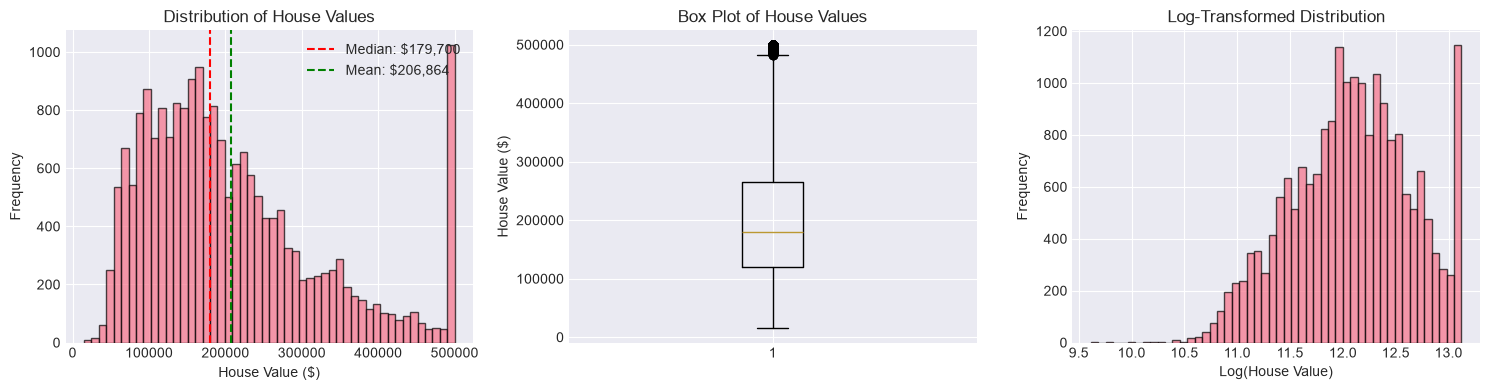

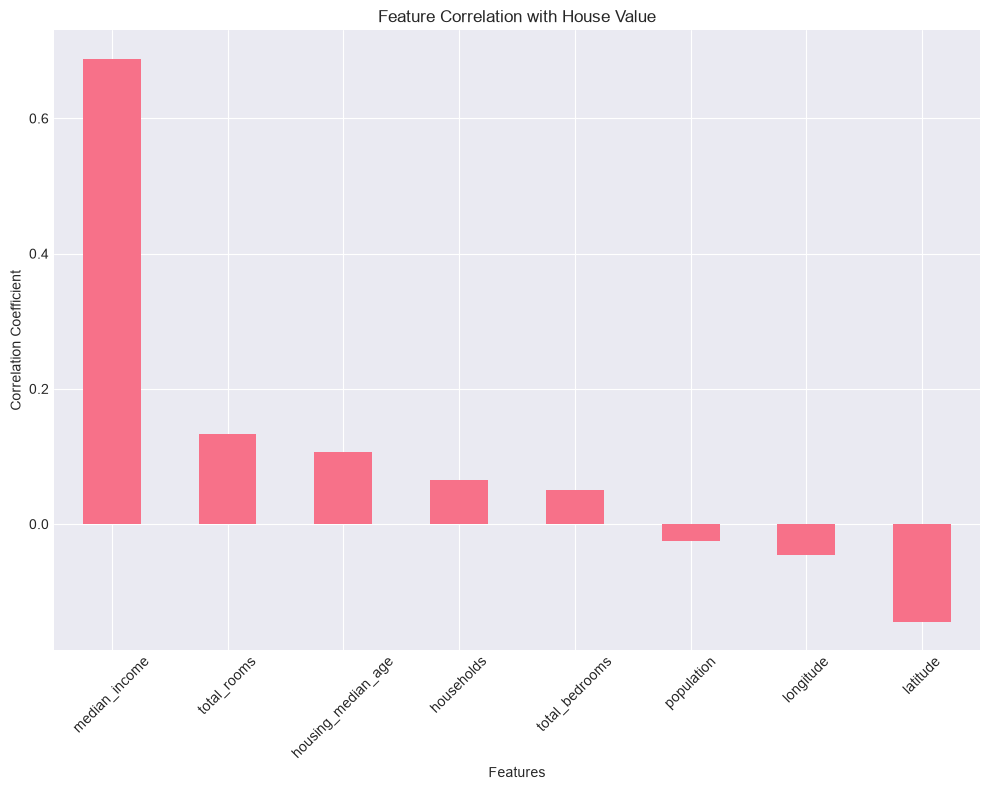

Top correlations with median_house_value:
median_house_value    1.000000
median_income         0.688355
total_rooms           0.133294
housing_median_age    0.106432
households            0.064894
total_bedrooms        0.049686
population           -0.025300
longitude            -0.045398
latitude             -0.144638
Name: median_house_value, dtype: float64


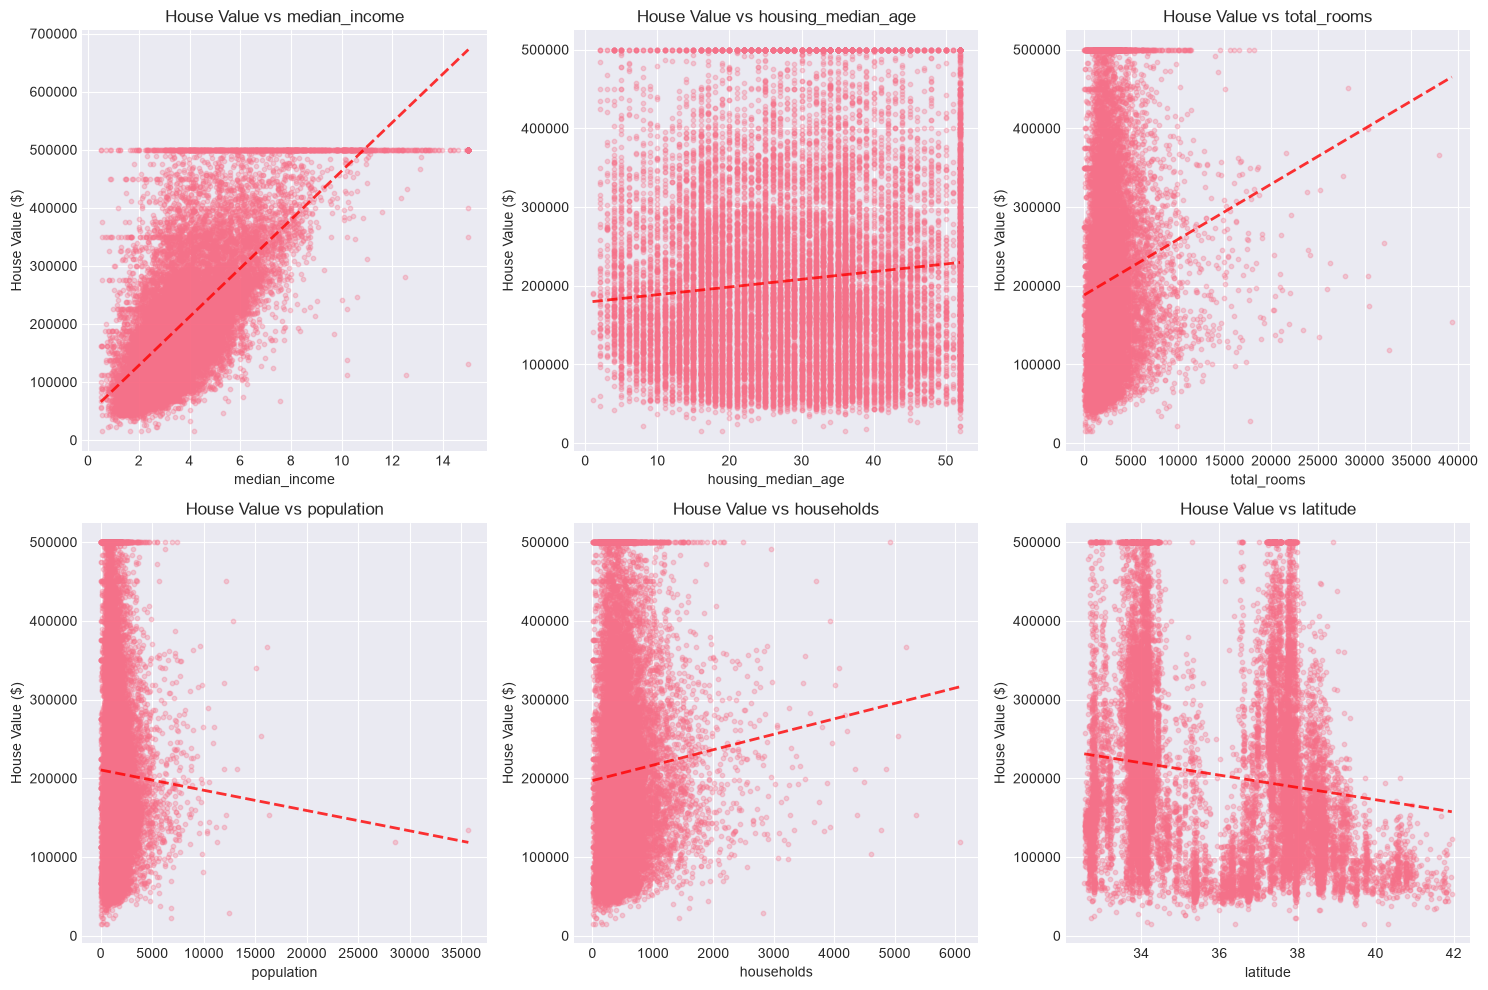

In [ ]:
# 3. Exploratory Data Analysis (EDA)

# Distribution of target variable
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Histogram
axes[0].hist(df['median_house_value'], bins=50, edgecolor='black', alpha=0.7)
axes[0].set_xlabel('House Value ($)')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Distribution of House Values')
axes[0].axvline(df['median_house_value'].median(), color='red', linestyle='--', 
                label=f'Median: ${df["median_house_value"].median():,.0f}')
axes[0].axvline(df['median_house_value'].mean(), color='green', linestyle='--', 
                label=f'Mean: ${df["median_house_value"].mean():,.0f}')
axes[0].legend()

# Box plot
axes[1].boxplot(df['median_house_value'])
axes[1].set_ylabel('House Value ($)')
axes[1].set_title('Box Plot of House Values')

# Log transform
axes[2].hist(np.log1p(df['median_house_value']), bins=50, edgecolor='black', alpha=0.7)
axes[2].set_xlabel('Log(House Value)')
axes[2].set_ylabel('Frequency')
axes[2].set_title('Log-Transformed Distribution')

plt.tight_layout()
plt.show()

# ==========================================
# Correlation with target variable
# ==========================================
numeric_cols = df.select_dtypes(include=[np.number]).columns

# Fixed broken line from the raw text
correlations = df[numeric_cols].corr()['median_house_value'].sort_values(ascending=False)

plt.figure(figsize=(10, 8))
correlations.drop('median_house_value').plot(kind='bar')
plt.title('Feature Correlation with House Value')
plt.xlabel('Features')
plt.ylabel('Correlation Coefficient')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Top correlations with median_house_value:")
print(correlations.head(10))

# ==========================================
# Scatter plots for important features
# ==========================================
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
features = ['median_income', 'housing_median_age', 'total_rooms', 'population', 'households', 'latitude']

# Fixed missing indentation inside the for-loop
for idx, feature in enumerate(features):
    row = idx // 3
    col = idx % 3
    
    axes[row, col].scatter(df[feature], df['median_house_value'], alpha=0.3, s=10)
    axes[row, col].set_xlabel(feature)
    axes[row, col].set_ylabel('House Value ($)')
    axes[row, col].set_title(f'House Value vs {feature}')
    
    # Add trend line
    z = np.polyfit(df[feature], df['median_house_value'], 1)
    p = np.poly1d(z)
    
    axes[row, col].plot(df[feature].sort_values(), p(df[feature].sort_values()), "r--", alpha=0.8, linewidth=2)

plt.tight_layout()
plt.show()

Training set size: 16346
Test set size: 4087

Univariate Linear Regression Model:
Equation: House Value = $45,035.23 + $41,751.96 * Median_Income
Interpretation: Each 1 unit increase in median income increases house value by $41,751.96

Univariate Model Performance:
Training RMSE: $83,418.33
Test RMSE: $84,976.53
Training R² Score: 0.4743
Test R² Score: 0.4720


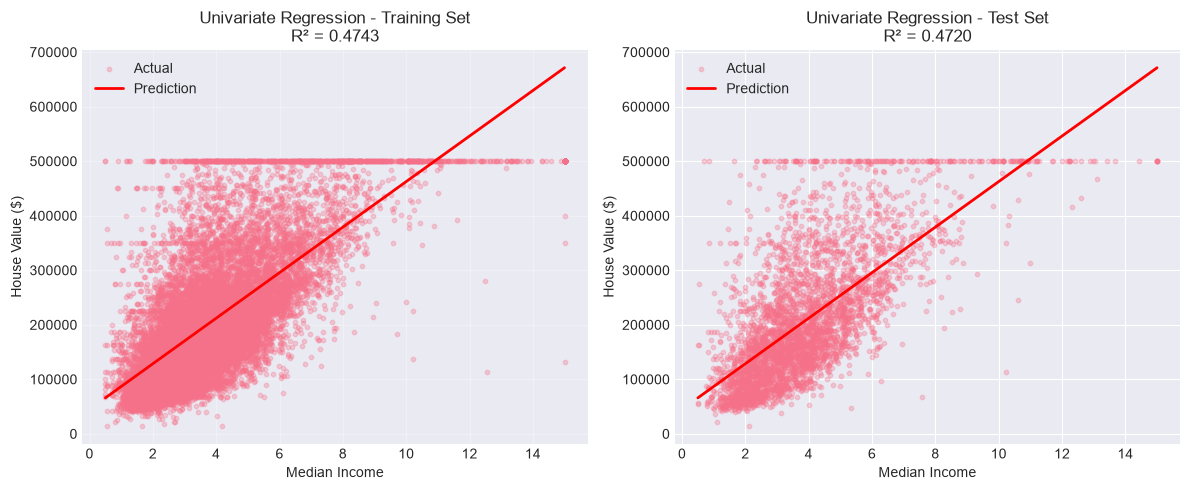

In [ ]:
# Prepare data for univariate regression 
X_univariate = df[['median_income']] 
y = df['median_house_value'] 

# Split data 
X_train_uni, X_test_uni, y_train, y_test = train_test_split( 
    X_univariate, y, test_size=0.2, random_state=42 
) 
print(f"Training set size: {X_train_uni.shape[0]}") 
print(f"Test set size: {X_test_uni.shape[0]}") 

# ==========================================
# Train univariate linear regression model 
# ==========================================
uni_model = LinearRegression() 
uni_model.fit(X_train_uni, y_train) 

# Get coefficients 
print("\nUnivariate Linear Regression Model:") 
print(f"Equation: House Value = ${uni_model.intercept_:,.2f} + ${uni_model.coef_[0]:,.2f} * Median_Income") 
print(f"Interpretation: Each 1 unit increase in median income increases house value by ${uni_model.coef_[0]:,.2f}") 

# ==========================================
# Make predictions 
# ==========================================
y_pred_uni_train = uni_model.predict(X_train_uni) 
y_pred_uni_test = uni_model.predict(X_test_uni) 

# Evaluate model 
train_rmse = np.sqrt(mean_squared_error(y_train, y_pred_uni_train)) 
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_uni_test)) 
train_r2 = r2_score(y_train, y_pred_uni_train) 
test_r2 = r2_score(y_test, y_pred_uni_test) 

print("\nUnivariate Model Performance:") 
print(f"Training RMSE: ${train_rmse:,.2f}") 
print(f"Test RMSE: ${test_rmse:,.2f}") 
print(f"Training R² Score: {train_r2:.4f}") 
print(f"Test R² Score: {test_r2:.4f}") 

# ==========================================
# Visualize univariate regression results
# ==========================================
plt.figure(figsize=(12, 5)) 

# Training data plot
plt.subplot(1, 2, 1) 
plt.scatter(X_train_uni, y_train, alpha=0.3, s=10, label='Actual') 
X_train_sorted = X_train_uni.sort_values('median_income') 
y_pred_sorted = uni_model.predict(X_train_sorted) 
plt.plot(X_train_sorted, y_pred_sorted, color='red', linewidth=2, label='Prediction') 
plt.xlabel('Median Income') 
plt.ylabel('House Value ($)') 
plt.title(f'Univariate Regression - Training Set\nR² = {train_r2:.4f}') 
plt.legend() 
plt.grid(True, alpha=0.3) 

# Test data plot
plt.subplot(1, 2, 2) 
plt.scatter(X_test_uni, y_test, alpha=0.3, s=10, label='Actual') 
X_test_sorted = X_test_uni.sort_values('median_income') 
y_pred_test_sorted = uni_model.predict(X_test_sorted) 
plt.plot(X_test_sorted, y_pred_test_sorted, color='red', linewidth=2, label='Prediction') 
plt.xlabel('Median Income') 
plt.ylabel('House Value ($)') 
plt.title(f'Univariate Regression - Test Set\nR² = {test_r2:.4f}') 
plt.legend() 

plt.tight_layout() 
plt.show()

In [ ]:

# 5. MULTIVARIATE LINEAR REGRESSION 
# Predicting house value using MULTIPLE features
# Encode categorical variable 'ocean_proximity' 
le = LabelEncoder() 
df['ocean_proximity_encoded'] = le.fit_transform(df['ocean_proximity']) 

# Select features for multivariate regression 
feature_cols = ['median_income', 'housing_median_age', 'total_rooms',  
                'total_bedrooms', 'population', 'households', 'latitude',  
                'longitude', 'ocean_proximity_encoded'] 
X_multivariate = df[feature_cols] 
y = df['median_house_value'] 

print(f"Selected features: {feature_cols}") 
print(f"Feature matrix shape: {X_multivariate.shape}") 

# Split data 
X_train_multi, X_test_multi, y_train, y_test = train_test_split( 
    X_multivariate, y, test_size=0.2, random_state=42 
) 

# Feature scaling (important for multivariate regression) 
scaler = StandardScaler() 
X_train_scaled = scaler.fit_transform(X_train_multi) 
X_test_scaled = scaler.transform(X_test_multi) 

# Train multivariate model 
multi_model = LinearRegression() 
multi_model.fit(X_train_scaled, y_train) 

# Display coefficients 
coef_df = pd.DataFrame({ 
    'Feature': feature_cols, 
    'Coefficient': multi_model.coef_, 
    'Abs_Coefficient': np.abs(multi_model.coef_) 
}).sort_values('Abs_Coefficient', ascending=False) 

print("\nMultivariate Linear Regression Model:") 
print(f"Intercept: ${multi_model.intercept_:,.2f}") 
print("\nFeature Coefficients (scaled - shows relative importance):") 
print(coef_df.to_string(index=False)) 

# Make predictions 
y_pred_multi_train = multi_model.predict(X_train_scaled) 
y_pred_multi_test = multi_model.predict(X_test_scaled) 

# Evaluate 
train_rmse_multi = np.sqrt(mean_squared_error(y_train, y_pred_multi_train)) 
test_rmse_multi = np.sqrt(mean_squared_error(y_test, y_pred_multi_test)) 
train_r2_multi = r2_score(y_train, y_pred_multi_train) 
test_r2_multi = r2_score(y_test, y_pred_multi_test) 

print("\nMultivariate Model Performance:") 
print(f"Training RMSE: ${train_rmse_multi:,.2f}") 
print(f"Test RMSE: ${test_rmse_multi:,.2f}") 
print(f"Training R² Score: {train_r2_multi:.4f}") 
print(f"Test R² Score: {test_r2_multi:.4f}")

Selected features: ['median_income', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'latitude', 'longitude', 'ocean_proximity_encoded']
Feature matrix shape: (20433, 9)

Multivariate Linear Regression Model:
Intercept: $206,644.40

Feature Coefficients (scaled - shows relative importance):
                Feature   Coefficient  Abs_Coefficient
               latitude -90748.672846     90748.672846
              longitude -85786.969310     85786.969310
          median_income  76403.230167     76403.230167
         total_bedrooms  48408.769307     48408.769307
             population -41646.359364     41646.359364
            total_rooms -18030.456130     18030.456130
             households  15673.527815     15673.527815
     housing_median_age  14548.787247     14548.787247
ocean_proximity_encoded   -561.222239       561.222239

Multivariate Model Performance:
Training RMSE: $69,409.70
Test RMSE: $70,172.00
Training R² Score: 0.6360
Test R² Score: 0

Model Comparison:
                      Model   Train RMSE    Test RMSE  Train R²  Test R²
   Univariate (Income Only) 83418.332580 84976.533256  0.474301 0.471962
Multivariate (All Features) 69409.696258 70171.995396  0.636039 0.639924


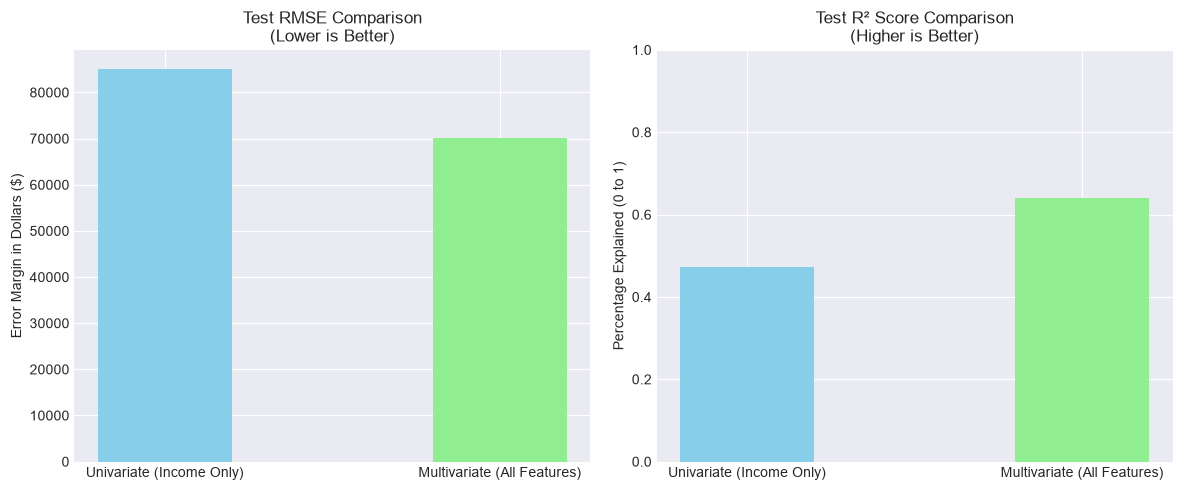

In [14]:

comparison = pd.DataFrame({ 
    'Model': ['Univariate (Income Only)', 'Multivariate (All Features)'], 
    'Train RMSE': [train_rmse, train_rmse_multi], 
    'Test RMSE': [test_rmse, test_rmse_multi], 
    'Train R²': [train_r2, train_r2_multi], 
    'Test R²': [test_r2, test_r2_multi] 
}) 

print("Model Comparison:") 
print(comparison.to_string(index=False)) 

# 2. Visual comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# RMSE Chart (Test RMSE)
axes[0].bar(comparison['Model'], comparison['Test RMSE'], color=['skyblue', 'lightgreen'], width=0.4)
axes[0].set_title("Test RMSE Comparison\n(Lower is Better)")
axes[0].set_ylabel("Error Margin in Dollars ($)")

# R² Score Chart (Test R²)
axes[1].bar(comparison['Model'], comparison['Test R²'], color=['skyblue', 'lightgreen'], width=0.4)
axes[1].set_title("Test R² Score Comparison\n(Higher is Better)")
axes[1].set_ylabel("Percentage Explained (0 to 1)")
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

In [ ]:
# MULTIVARIATE REGRESSION (FILTERED CLEAN DATA)
# 1. Filter out the artificial price floors and ceilings
df_clean = df[(df['median_house_value'] > 50000) & (df['median_house_value'] < 500000)].copy()

print(f"Original dataset size: {len(df)}")
print(f"Cleaned dataset size: {len(df_clean)}")
print(f"Rows removed: {len(df) - len(df_clean)}\n")

# 2. Re-encode categorical variable on the clean data
le = LabelEncoder() 
df_clean['ocean_proximity_encoded'] = le.fit_transform(df_clean['ocean_proximity']) 

# 3. Select features and target
feature_cols = ['median_income', 'housing_median_age', 'total_rooms',  
                'total_bedrooms', 'population', 'households', 'latitude',  
                'longitude', 'ocean_proximity_encoded'] 
X_clean = df_clean[feature_cols] 
y_clean = df_clean['median_house_value'] 

# 4. Split data (80/20)
X_train_clean, X_test_clean, y_train_clean, y_test_clean = train_test_split( 
    X_clean, y_clean, test_size=0.2, random_state=42 
) 

# 5. Feature scaling (preventing data leakage)
scaler = StandardScaler() 
X_train_scaled_clean_multi = scaler.fit_transform(X_train_clean) 
X_test_scaled_clean_multi = scaler.transform(X_test_clean) 

# 6. Train the newly filtered model
clean_model = LinearRegression() 
clean_model.fit(X_train_scaled_clean_multi, y_train_clean) 

# 7. Make predictions
y_pred_train_clean = clean_model.predict(X_train_scaled_clean_multi) 
y_pred_test_clean = clean_model.predict(X_test_scaled_clean_multi) 

# 8. Evaluate
train_rmse_clean_multi = np.sqrt(mean_squared_error(y_train_clean, y_pred_train_clean)) 
test_rmse_clean_multi = np.sqrt(mean_squared_error(y_test_clean, y_pred_test_clean)) 
train_r2_clean_multi = r2_score(y_train_clean, y_pred_train_clean) 
test_r2_clean_multi = r2_score(y_test_clean, y_pred_test_clean) 

print("FILTERED Multivariate Model Performance:") 
print(f"Training RMSE: ${train_rmse_clean_multi:,.2f}") 
print(f"Test RMSE: ${test_rmse_clean_multi:,.2f}") 
print(f"Training R² Score: {train_r2_clean_multi:.4f}") 
print(f"Test R² Score: {test_r2_clean_multi:.4f}")



Original dataset size: 20433
Cleaned dataset size: 19242
Rows removed: 1191

FILTERED Multivariate Model Performance:
Training RMSE: $60,827.45
Test RMSE: $62,446.45
Training R² Score: 0.6029
Test R² Score: 0.5745


=== Performance Comparison ===


,Model,RMSE,R2 Score
0,Previous Multivariate,70171.995396,0.639924
1,Cleaned Multivariate,62446.453037,0.574523


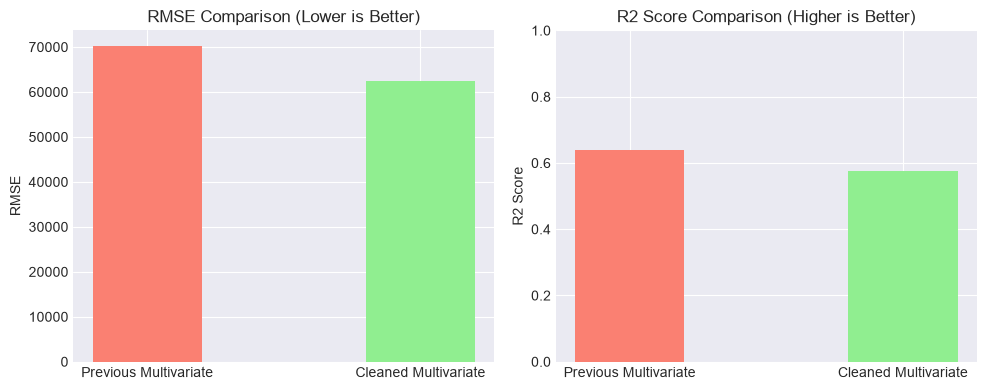

In [ ]:
# Compare Performance: Previous vs Cleaned Multivariate

# 1. Comparison Table
# FIXED: Updated variable names to match the cleaned model's exact outputs
comparison_df = pd.DataFrame({
    "Model": ["Previous Multivariate", "Cleaned Multivariate"],
    "RMSE": [test_rmse_multi, test_rmse_clean],
    "R2 Score": [test_r2_multi, test_r2_clean]
})

print("=== Performance Comparison ===")
display(comparison_df)

# 2. Visual Comparison
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# RMSE (Lower is better)
axes[0].bar(comparison_df["Model"], comparison_df["RMSE"], color=['salmon', 'lightgreen'], width=0.4)
axes[0].set_title("RMSE Comparison (Lower is Better)")
axes[0].set_ylabel("RMSE")

# R2 Score (Higher is better)
axes[1].bar(comparison_df["Model"], comparison_df["R2 Score"], color=['salmon', 'lightgreen'], width=0.4)
axes[1].set_title("R2 Score Comparison (Higher is Better)")
axes[1].set_ylabel("R2 Score")
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()